# <div style="background-color:rgba(255, 255, 255, 0.1); text-align:center; vertical-align: middle; padding:40px 0; margin-top:30px"><span style="color:rgba(255, 255, 255, 1);"> AC SF-57 Green Laser</span></span></div>

In [2]:
# Hide unnecessary warnings.
import warnings
warnings.filterwarnings('ignore')

# Import PHYS231.py and then run the installer function.
import PHYS231
PHYS231.Installer()

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm # used to generate a sequence of colours for plotting
import pandas as pd
import scipy.stats as sp
from scipy.optimize import curve_fit
from IPython.display import HTML as html_print
from IPython.display import display, Markdown, Latex
import uncertainties
import math
import sys

In [4]:
from IPython.display import HTML, display


def variable_template_builder():
    html_code = """
    <div style="background-color: #1e1e1e; padding: 15px; border-radius: 8px; font-family: sans-serif; max-width: 520px; color: #ffffff; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
        <div style="margin-bottom: 10px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Variable Name(s) (comma-separated):</label>
            <input type="text" id="var_names_input" placeholder="e.g. theta_m, I, B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>
        <div style="margin-bottom: 14px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Units / Comment (Optional, comma-separated):</label>
            <input type="text" id="units_comment_input" placeholder="e.g. deg, A, T" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>
        <button id="copy_btn" onclick="copyAndReset()" style="width: 100%; padding: 10px; background-color: #2da44e; color: white; border: none; border-radius: 6px; font-weight: bold; cursor: pointer; transition: background-color 0.2s;">
            Copy Template & Reset
        </button>
    </div>

    <script>
    function copyAndReset() {
        const varInput = document.getElementById('var_names_input');
        const commentInput = document.getElementById('units_comment_input');
        const btn = document.getElementById('copy_btn');
        
        const vars = varInput.value.split(',').map(s => s.trim()).filter(s => s.length > 0);
        const comments = commentInput.value.split(',').map(s => s.trim());
        
        if (vars.length === 0) {
            btn.innerText = 'Please enter at least one variable name!';
            btn.style.backgroundColor = '#d73a49';
            setTimeout(() => { 
                btn.innerText = 'Copy Template & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
            return;
        }
        
        let lines = [];
        vars.forEach((v, idx) => {
            let comment = comments[idx] !== undefined ? comments[idx] : (comments[0] || '');
            let commentStr = comment ? `  # ${comment}` : '';
            lines.push(`${v} = np.array([])${commentStr}`);
            lines.push(`err_${v} = np.full_like(${v}, 0.0)\\n`);
        });
        
        const fullCode = lines.join('\\n').trim();
        
        navigator.clipboard.writeText(fullCode).then(() => {
            btn.innerText = 'Copied to Clipboard & Cleared!';
            btn.style.backgroundColor = '#1f6feb';
            varInput.value = '';
            commentInput.value = '';
            setTimeout(() => { 
                btn.innerText = 'Copy Template & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
        });
    }
    </script>
    """
    display(HTML(html_code))


# Run to render the interactive widget block
variable_template_builder()

In [5]:
from IPython.display import HTML, display


def graph_template_builder():
    html_code = """
    <div style="background-color: #1e1e1e; padding: 18px; border-radius: 8px; font-family: sans-serif; max-width: 540px; color: #ffffff; box-shadow: 0 4px 6px rgba(0,0,0,0.3);">
        
        <div style="margin-bottom: 12px;">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Graph / Analysis Type:</label>
            <select id="graph_type" onchange="updateFields()" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; font-family: sans-serif;">
                <option value="LinearFit">Linear Fit (PHYS231.LinearFit)</option>
                <option value="Scatter">Scatter Plot (PHYS231.Scatter)</option>
                <option value="PowerLaw">Power Law Fit (PHYS231.PowerLaw)</option>
                <option value="Charging">RC Charging Fit (PHYS231.Charging)</option>
                <option value="Sine">Sine Wave Fit (PHYS231.Sine)</option>
                <option value="Braking">Magnetic Braking Fit (PHYS231.Braking)</option>
                <option value="Statistics">Histogram & Stats (PHYS231.Statistics)</option>
            </select>
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 10px;">
            <div id="box_xData">
                <label id="lbl_xData" style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Data Variable:</label>
                <input type="text" id="xData_input" placeholder="e.g. I" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_yData">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Data Variable:</label>
                <input type="text" id="yData_input" placeholder="e.g. B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="margin-bottom: 10px;" id="box_yErrors">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Errors Variable:</label>
            <input type="text" id="yErrors_input" placeholder="e.g. err_B" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 10px;">
            <div>
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Axis Label:</label>
                <input type="text" id="xlabel_input" placeholder="e.g. Current" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_ylabel">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Axis Label:</label>
                <input type="text" id="ylabel_input" placeholder="e.g. Magnetic Field" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="display: grid; grid-template-columns: 1fr 1fr; gap: 10px; margin-bottom: 12px;">
            <div>
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">X Units:</label>
                <input type="text" id="xUnits_input" placeholder="e.g. A" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
            <div id="box_yUnits">
                <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Y Units:</label>
                <input type="text" id="yUnits_input" placeholder="e.g. mT" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
            </div>
        </div>

        <div style="margin-bottom: 14px; display: none;" id="box_nbins">
            <label style="display: block; font-size: 12px; font-weight: bold; margin-bottom: 4px; color: #cccccc;">Number of Bins:</label>
            <input type="text" id="nbins_input" placeholder="10" value="10" style="width: 100%; padding: 8px; border-radius: 4px; border: 1px solid #444; background: #2d2d2d; color: white; box-sizing: border-box; font-family: monospace;">
        </div>

        <button id="graph_copy_btn" onclick="copyAndResetGraph()" style="width: 100%; padding: 10px; background-color: #2da44e; color: white; border: none; border-radius: 6px; font-weight: bold; cursor: pointer; transition: background-color 0.2s;">
            Copy Graph Code & Reset
        </button>
    </div>

    <script>
    function updateFields() {
        const type = document.getElementById('graph_type').value;
        const isStats = (type === 'Statistics');

        document.getElementById('box_yData').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_yErrors').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_ylabel').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_yUnits').style.display = isStats ? 'none' : 'block';
        document.getElementById('box_nbins').style.display = isStats ? 'block' : 'none';

        document.getElementById('lbl_xData').innerText = isStats ? 'Data Variable:' : 'X Data Variable:';
    }

    function copyAndResetGraph() {
        const type = document.getElementById('graph_type').value;
        const xData = document.getElementById('xData_input').value.trim() || 'x_data';
        const yData = document.getElementById('yData_input').value.trim() || 'y_data';
        const yErrors = document.getElementById('yErrors_input').value.trim() || 'err_y_data';
        const xlabel = document.getElementById('xlabel_input').value.trim();
        const ylabel = document.getElementById('ylabel_input').value.trim();
        const xUnits = document.getElementById('xUnits_input').value.trim();
        const yUnits = document.getElementById('yUnits_input').value.trim();
        const nbins = document.getElementById('nbins_input').value.trim() || '10';

        let code = '';

        if (type === 'LinearFit') {
            code = `slope, intercept, err_slope, err_intercept, fig = PHYS231.LinearFit(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}",\\n    fill=False\\n)`;
        } else if (type === 'Scatter') {
            code = `fig = PHYS231.Scatter(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}",\\n    fill=False,\\n    show=True\\n)`;
        } else if (type === 'PowerLaw') {
            code = `coeff, power, offset, errA, errN, errC, fig = PHYS231.PowerLaw(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Charging') {
            code = `A, tau, errA, errTau, fig = PHYS231.Charging(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Sine') {
            code = `amp, period, phase, errA, errT, errPhi, fig = PHYS231.Sine(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Braking') {
            code = `v_term, tau, err_v, err_tau, fig = PHYS231.Braking(\\n    xData=${xData},\\n    yData=${yData},\\n    yErrors=${yErrors},\\n    xlabel="${xlabel}",\\n    ylabel="${ylabel}",\\n    xUnits="${xUnits}",\\n    yUnits="${yUnits}"\\n)`;
        } else if (type === 'Statistics') {
            code = `counts, centres, mean, std_dev, std_err, fig = PHYS231.Statistics(\\n    data=${xData},\\n    nbins=${nbins},\\n    xlabel="${xlabel}",\\n    xUnits="${xUnits}",\\n    normalized=False\\n)`;
        }

        const btn = document.getElementById('graph_copy_btn');

        navigator.clipboard.writeText(code).then(() => {
            btn.innerText = 'Copied Code to Clipboard & Cleared!';
            btn.style.backgroundColor = '#1f6feb';
            
            // Clear input fields
            document.getElementById('xData_input').value = '';
            document.getElementById('yData_input').value = '';
            document.getElementById('yErrors_input').value = '';
            document.getElementById('xlabel_input').value = '';
            document.getElementById('ylabel_input').value = '';
            document.getElementById('xUnits_input').value = '';
            document.getElementById('yUnits_input').value = '';
            
            setTimeout(() => { 
                btn.innerText = 'Copy Graph Code & Reset'; 
                btn.style.backgroundColor = '#2da44e';
            }, 2000);
        });
    }
    </script>
    """
    display(HTML(html_code))


graph_template_builder()

# Green Laser notes

Green Laser has pulses in signal so we don't see a nice sin function, to get rid of those large puslses, we need to add a low pass filter of the right time constant so as to not average out our reference signal but get rid of the pulses, viewed on an oscilloscope we can see that 0.5 seconds is the goldylock zone.

Currently at 3k Ohms

In [12]:
V_dc = 0.04367  # DC baseline photodetector voltage at 45 degrees (Volts)  ie 45 degrees from the extinction point.
err_V_dc = 0.0001

I_sol = np.array([0.1073, 0.2079, 0.3023, 0.4272, 0.5412, 0.6361, 0.7596, 0.8531, 0.9614])  # AC Current of solenoid in Amperes Note to Self use RMS or Peak
err_I_sol = np.full_like(I_sol, 0.0005)

freq = 50 # Modulation Frequency in Hz
err_freq = 1

L = 0.1  # Length of sample in meters
err_L = 0.001

B = (11.1 * I_sol) / 1000  # Magnetic Field Strength in Tesla (converting 11.1 mT/A to T)
err_B = (11.1 * err_I_sol) / 1000

V_ac_mV_RMS = np.array([0.305, 0.58, 0.85, 1.212, 1.537, 1.825, 2.17, 2.465, 2.76])  # AC signal voltage from Lock-In Amplifier (mV)

V_ac = V_ac_mV_RMS/1000

err_V_ac_mV_RMS = np.full_like(V_ac, 0.01)

err_V_ac = (err_V_ac_mV_RMS*np.sqrt(2))/1000

theta_ac_rad = V_ac / (2 * V_dc)# Faraday rotation angle in radians (from Lock-In amplitude: theta_ac = V_ac / (2 * V_dc)) See Derivation!
err_theta_ac_rad = theta_ac_rad * np.sqrt((err_V_ac / V_ac)**2 + (err_V_dc / V_dc)**2)

$y = m\,x + b$

This is a **WEIGHTED** fit.

,,Value,Units
slope,$m =$,2.982+/-0.012,rad/T
$y$-intercept,$b =$,-0.000208+/-0.000080,rad


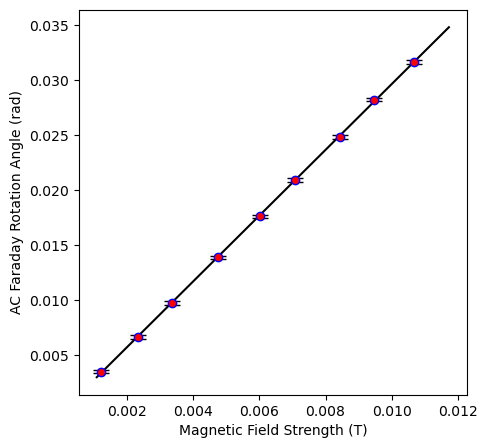

In [13]:
slope, intercept, err_slope, err_intercept, fig = PHYS231.LinearFit(
    xData=B,
    yData=theta_ac_rad,
    yErrors=err_theta_ac_rad,
    xlabel="Magnetic Field Strength",
    ylabel="AC Faraday Rotation Angle",
    xUnits="T",
    yUnits="rad",
    fill=False,
)

In [14]:
V = slope / L  # Units: rad / (T * m)
err_V = V * np.sqrt((err_slope / slope) ** 2 + (err_L / L) ** 2)

print(f"Verdet Constant (V): {V:.2f} +/- {err_V:.2f} rad/(T*m)")

Verdet Constant (V): 29.82 +/- 0.32 rad/(T*m)


### Derivation of Faraday Rotation Angle from AC and DC Voltages for understanding

The relationship $\theta = \frac{V_{\text{ac}}}{2 V_{\text{dc}}}$ is derived by applying **Malus's Law** at a $45^\circ$ bias point, combined with a **small-angle approximation**.

---

#### Step 1: Malus's Law at a $45^\circ$ Bias
The optical power reaching the photodetector follows Malus's Law:

$$I(\phi) = I_{\text{max}} \cos^2(\phi)$$

where $\phi$ is the angle between the linear polarization of light and the transmission axis of the analyzer.

In Method 3 (AC method), the analyzer is set to a baseline bias angle of $45^\circ$ ($\frac{\pi}{4}\text{ rad}$) before applying the alternating magnetic field. When the AC magnetic field fluctuates, it induces a small time-varying Faraday rotation angle $\theta(t)$ on top of that $45^\circ$ offset:

$$\phi(t) = \frac{\pi}{4} + \theta(t)$$

Substituting this into Malus's Law:

$$I(t) = I_{\text{max}} \cos^2\left(\frac{\pi}{4} + \theta(t)\right)$$

---

#### Step 2: Trigonometric Identity
Using the double-angle identity $\cos^2(x) = \frac{1 + \cos(2x)}{2}$:

$$I(t) = \frac{I_{\text{max}}}{2} \left[ 1 + \cos\left(\frac{\pi}{2} + 2\theta(t)\right) \right]$$

Since $\cos\left(\frac{\pi}{2} + x\right) = -\sin(x)$, this simplifies to:

$$I(t) = \frac{I_{\text{max}}}{2} \left[ 1 - \sin(2\theta(t)) \right]$$

---

#### Step 3: Small-Angle Approximation
Because Faraday rotation angles in typical lab setups are extremely small ($\theta \ll 1\text{ rad}$), apply the small-angle approximation $\sin(x) \approx x$, which gives $\sin(2\theta) \approx 2\theta$:

$$I(t) \approx \frac{I_{\text{max}}}{2} \left[ 1 - 2\theta(t) \right] = \frac{I_{\text{max}}}{2} - I_{\text{max}}\theta(t)$$

---

#### Step 4: Separating DC and AC Voltage Components
A photodetector converts light intensity $I(t)$ into a proportional output voltage $V(t) = G \cdot I(t)$, where $G$ represents the detector gain/sensitivity:

$$V(t) = \underbrace{\frac{G \cdot I_{\text{max}}}{2}}_{\text{DC Signal } (V_{\text{dc}})} - \underbrace{G \cdot I_{\text{max}} \cdot \theta(t)}_{\text{AC Signal } (V_{\text{ac}})}$$

Separating these two components yields:

1. **Steady DC Voltage:**
   $$V_{\text{dc}} = \frac{G \cdot I_{\text{max}}}{2} \implies G \cdot I_{\text{max}} = 2 V_{\text{dc}}$$

2. **Oscillating AC Voltage Amplitude:**
   $$V_{\text{ac}} = G \cdot I_{\text{max}} \cdot \theta$$

---

#### Step 5: Solving for the Faraday Rotation Angle ($\theta$)
Substitute $G \cdot I_{\text{max}} = 2 V_{\text{dc}}$ into the AC voltage equation:

$$V_{\text{ac}} = (2 V_{\text{dc}}) \cdot \theta$$

Rearranging to solve for the rotation angle $\theta$ (in radians):

$$\theta = \frac{V_{\text{ac}}}{2 V_{\text{dc}}}$$



In [9]:
import numpy as np
import pandas as pd
from IPython.display import display, Math

def show_calc(lhs, *rhs_steps):
    """
    Displays a multi-step calculation in an aligned LaTeX block.
    
    Parameters:
    lhs (str): The left-hand side of the equation (e.g., r'F_{net}').
    *rhs_steps (str): The sequential steps for the right-hand side.
                      e.g., r'm \cdot a', r'(5.0 \text{ kg})(2.0 \text{ m/s}^2)', r'10.0 \text{ N}'
    """
    if not rhs_steps:
        display(Math(lhs))
        return
        
    # Build the aligned LaTeX string
    latex_str = r"\begin{aligned} "
    latex_str += f"{lhs} &= {rhs_steps[0]} \\\\[1ex] "
    for step in rhs_steps[1:]:
        latex_str += f"&= {step} \\\\[1ex] "
    latex_str += r"\end{aligned}"
    
    display(Math(latex_str))

def display_table(data_dict, caption=None, precision=3):
    """
    Displays a formatted table supporting LaTeX column names and numpy arrays.
    
    Parameters:
    data_dict (dict): Keys are column headers (supports LaTeX, e.g., '$v_f$ (m/s)'), 
                      Values are lists, numpy arrays, or single scalar variables.
    caption (str): Optional title for the table.
    precision (int): Number of decimal places to display for float values.
    """
    # Find the maximum array length to handle single variables alongside arrays
    lengths = [len(v) if hasattr(v, '__len__') and not isinstance(v, str) else 1 for v in data_dict.values()]
    max_len = max(lengths) if lengths else 1
    
    # Broadcast scalar values to match the array length
    processed_dict = {}
    for k, v in data_dict.items():
        if not hasattr(v, '__len__') or isinstance(v, str):
            processed_dict[k] = [v] * max_len 
        else:
            processed_dict[k] = v
            
    df = pd.DataFrame(processed_dict)
    
    # Apply Pandas styling for center alignment and decimal control
    styled_df = df.style.format(precision=precision) \
                        .set_properties(**{'text-align': 'center'}) \
                        .set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
    
    if caption:
        styled_df = styled_df.set_caption(f"<div style='font-size:1.2em; font-weight:bold; margin-bottom:10px;'>{caption}</div>")
        
    display(styled_df)

In [17]:
import numpy as np
import pandas as pd
from IPython.display import display, Math, Markdown

# =========================================================================
# 1. Helper Functions for LaTeX Calculations & Formatting
# =========================================================================

def show_calc(lhs, *rhs_steps):
    """Displays a multi-step calculation in an aligned LaTeX block."""
    if not rhs_steps:
        display(Math(lhs))
        return
        
    latex_str = r"\begin{aligned} "
    latex_str += f"{lhs} &= {rhs_steps[0]} \\\\[1ex] "
    for step in rhs_steps[1:]:
        latex_str += f"&= {step} \\\\[1ex] "
    latex_str += r"\end{aligned}"
    
    display(Math(latex_str))

def display_table(data_dict, caption=None, precision=4):
    """Displays a formatted table supporting LaTeX headers and numpy arrays."""
    lengths = [len(v) if hasattr(v, '__len__') and not isinstance(v, str) else 1 for v in data_dict.values()]
    max_len = max(lengths) if lengths else 1
    
    processed_dict = {}
    for k, v in data_dict.items():
        if not hasattr(v, '__len__') or isinstance(v, str):
            processed_dict[k] = [v] * max_len 
        else:
            processed_dict[k] = v
            
    df = pd.DataFrame(processed_dict)
    
    styled_df = df.style.format(precision=precision) \
                        .set_properties(**{'text-align': 'center'}) \
                        .set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
    
    if caption:
        styled_df = styled_df.set_caption(f"<div style='font-size:1.2em; font-weight:bold; margin-bottom:10px;'>{caption}</div>")
        
    display(styled_df)


# =========================================================================
# 2. Experimental Data & Calculations
# =========================================================================

# Fixed / Scalar Parameters
V_dc = 0.04367          # Volts
err_V_dc = 0.0001

freq = 50               # Hz
err_freq = 1

L = 0.1                 # meters
err_L = 0.001

# Array Data
I_sol = np.array([0.1073, 0.2079, 0.3023, 0.4272, 0.5412, 0.6361, 0.7596, 0.8531, 0.9614])
err_I_sol = np.full_like(I_sol, 0.0005)

# Magnetic Field (T)
B = (11.1 * I_sol) / 1000
err_B = (11.1 * err_I_sol) / 1000

# AC Voltage Signal (mV RMS -> V peak)
V_ac_mV_RMS = np.array([0.305, 0.58, 0.85, 1.212, 1.537, 1.825, 2.17, 2.465, 2.76])
err_V_ac_mV_RMS = np.full_like(V_ac_mV_RMS, 0.01)

V_ac = (V_ac_mV_RMS * np.sqrt(2)) / 1000
err_V_ac = (err_V_ac_mV_RMS * np.sqrt(2)) / 1000

# Faraday Rotation Angle (rad) & Error Propagation
theta_ac_rad = V_ac / (2 * V_dc)
err_theta_ac_rad = theta_ac_rad * np.sqrt((err_V_ac / V_ac)**2 + (err_V_dc / V_dc)**2)

# Linear Regression to extract slope (theta vs B)
poly, cov = np.polyfit(B, theta_ac_rad, 1, cov=True)
slope = poly[0]
err_slope = np.sqrt(cov[0, 0])

# Verdet Constant Calculation
V = slope / L
err_V = V * np.sqrt((err_slope / slope)**2 + (err_L / L)**2)


# =========================================================================
# 3. Display Results in Notebook
# =========================================================================

# --- A. Data Table ---
lab_data = {
    r"Trial": np.arange(1, len(I_sol) + 1),
    r"$I_{\text{sol}}$ (A)": I_sol,
    r"$B$ (T)": B,
    r"$V_{\text{ac, RMS}}$ (mV)": V_ac_mV_RMS,
    r"$V_{\text{ac}}$ (V)": V_ac,
    r"$\theta_{\text{ac}}$ (rad)": theta_ac_rad,
    r"$\delta \theta_{\text{ac}}$ (rad)": err_theta_ac_rad,
}

display_table(lab_data, caption="Faraday Effect Experimental Measurements", precision=5)


# --- B. Step-by-Step Sample Calculations (for Trial 1) ---
display(Markdown("### Sample Calculations (Trial 1)"))

# 1. Magnetic Field B
show_calc(
    r"B_1",
    r"\frac{11.1 \cdot I_{\text{sol, 1}}}{1000}",
    rf"\frac{{11.1 \cdot {I_sol[0]}}}{{1000}}",
    rf"{B[0]:.6f} \text{{ T}}"
)

# 2. AC Peak Voltage Conversion
show_calc(
    r"V_{\text{ac, 1}}",
    r"\frac{V_{\text{ac, RMS, 1}} \cdot \sqrt{2}}{1000}",
    rf"\frac{{{V_ac_mV_RMS[0]}}} \cdot \sqrt{{2}}{{1000}}",
    rf"{V_ac[0]:.6f} \text{{ V}}"
)

# 3. Faraday Rotation Angle theta
show_calc(
    r"\theta_{\text{ac, 1}}",
    r"\frac{V_{\text{ac, 1}}}{2 \cdot V_{\text{dc}}}",
    rf"\frac{{{V_ac[0]:.6f}}}{{2 \cdot {V_dc}}}",
    rf"{theta_ac_rad[0]:.6f} \text{{ rad}}"
)

# 4. Uncertainty in theta
show_calc(
    r"\delta \theta_{\text{ac, 1}}",
    r"\theta_{\text{ac, 1}} \cdot \sqrt{\left(\frac{\delta V_{\text{ac}}}{V_{\text{ac, 1}}}\right)^2 + \left(\frac{\delta V_{\text{dc}}}{V_{\text{dc}}}\right)^2}",
    rf"{theta_ac_rad[0]:.6f} \cdot \sqrt{{\left(\frac{{{err_V_ac[0]:.6f}}}{{{V_ac[0]:.6f}}}\right)^2 + \left(\frac{{{err_V_dc}}}{{{V_dc}}}\right)^2}}",
    rf"{err_theta_ac_rad[0]:.6f} \text{{ rad}}"
)

# 5. Final Verdet Constant
display(Markdown("### Final Results"))
show_calc(
    r"V",
    r"\frac{\text{slope}}{L}",
    rf"\frac{{{slope:.4f}}}{{{L}}}",
    rf"{V:.2f} \pm {err_V:.2f} \text{{ rad}}/(\text{{T}} \cdot \text{{m}})"
)

,Trial,$I_{\text{sol}}$ (A),$B$ (T),"$V_{\text{ac, RMS}}$ (mV)",$V_{\text{ac}}$ (V),$\theta_{\text{ac}}$ (rad),$\delta \theta_{\text{ac}}$ (rad)
0,1,0.10730,0.00119,0.30500,0.00043,0.00494,0.00016
1,2,0.20790,0.00231,0.58000,0.00082,0.00939,0.00016
2,3,0.30230,0.00336,0.85000,0.00120,0.01376,0.00016
3,4,0.42720,0.00474,1.21200,0.00171,0.01962,0.00017
4,5,0.54120,0.00601,1.53700,0.00217,0.02489,0.00017
5,6,0.63610,0.00706,1.82500,0.00258,0.02955,0.00018
6,7,0.75960,0.00843,2.17000,0.00307,0.03514,0.00018
7,8,0.85310,0.00947,2.46500,0.00349,0.03991,0.00019
8,9,0.96140,0.01067,2.76000,0.00390,0.04469,0.00019


### Sample Calculations (Trial 1)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Final Results

<IPython.core.display.Math object>